In [ ]:
# TODO: View effects of IsolationForest hyperparameters on proximity-based visualization.

# IsolationForest Anomaly Detection with PHATE Visualization

This notebook demonstrates:
1. Fitting an IsolationForest model for unsupervised anomaly detection
2. Generating sparse random forest approximation (RFGAP) proximities
3. Computing PHATE embeddings from the proximity matrix
4. Visualizing anomalies in the embedded space

In [1]:
from pathlib import Path
import sys

# Add parent directory to path to import local forestgap package
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
import warnings

from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest

from forestgap import with_sparse_proximity

warnings.filterwarnings(
    "ignore",
    message=r".*BaseEstimator\._validate_data.*",
    category=FutureWarning,
)

try:
    import phate
except ImportError:
    raise ImportError(
        "PHATE is required for this tutorial. Install with: pip install phate"
    )

## Configuration

In [2]:
# Global configuration
RANDOM_STATE = 42
N_ESTIMATORS = 100
N_JOBS = -1  # Use all available CPU cores
CONTAMINATION = 0.1  # Expected fraction of anomalies (10%)
BOOTSTRAP = True  # Use bootstrapped samples for anomaly detection
PROX_METHOD = "rfgap"  # Proximity computation method

print(f"IsolationForest Configuration:")
print(f"  N_ESTIMATORS: {N_ESTIMATORS}")
print(f"  CONTAMINATION: {CONTAMINATION}")
print(f"  BOOTSTRAP: {BOOTSTRAP}")
print(f"  PROX_METHOD: {PROX_METHOD}")
print(f"  N_JOBS: {N_JOBS}")

IsolationForest Configuration:
  N_ESTIMATORS: 100
  CONTAMINATION: 0.1
  BOOTSTRAP: True
  PROX_METHOD: rfgap
  N_JOBS: -1


## Synthetic Data Generation

We generate synthetic data with clusters and then inject outliers to simulate anomalies.

In [3]:
# Generate synthetic dataset with clusters
np.random.seed(RANDOM_STATE)
n_samples = 300
n_features = 2

# Generate main clusters
X_clusters, _ = make_blobs(
    n_samples=int(n_samples * (1 - CONTAMINATION)),
    n_features=n_features,
    centers=4,
    random_state=RANDOM_STATE,
    cluster_std=0.6,
)

# Generate outlier points (anomalies)
n_outliers = int(n_samples * CONTAMINATION)
X_outliers = np.random.uniform(
    low=X_clusters.min(axis=0) - 5,
    high=X_clusters.max(axis=0) + 5,
    size=(n_outliers, n_features),
)

# Combine data
X = np.vstack([X_clusters, X_outliers])
y_true = np.hstack([
    np.zeros(len(X_clusters), dtype=int),
    np.ones(len(X_outliers), dtype=int)
])

# Standardize features
scaler = StandardScaler()
X = scaler.fit_transform(X)

print(f"Dataset shape: {X.shape}")
print(f"Number of normal samples: {(y_true == 0).sum()}")
print(f"Number of anomalies (true): {(y_true == 1).sum()}")

Dataset shape: (300, 2)
Number of normal samples: 270
Number of anomalies (true): 30


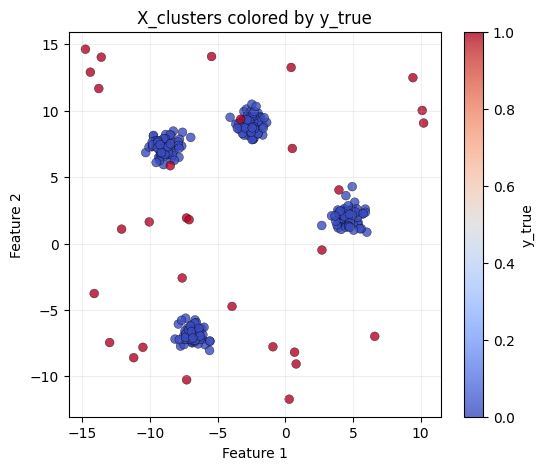

In [12]:
# Simple scatterplot of X_clusters colored by y_true (aligned length)
plt.figure(figsize=(6, 5))
X_all = np.vstack([X_clusters, X_outliers])

plt.scatter(
    X_all[:, 0],
    X_all[:, 1],
    c=y_true,
    cmap="coolwarm",
    s=40,
    alpha=0.8,
    edgecolors="k",
    linewidth=0.3,
)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("X_clusters colored by y_true")
plt.colorbar(label="y_true")
plt.grid(alpha=0.2)
plt.show()

## IsolationForest Fitting and Anomaly Detection

In [4]:
# Create IsolationForest with sparse proximity support
IsoForestWithProx = with_sparse_proximity(IsolationForest)

iso_forest = IsoForestWithProx(
    n_estimators=N_ESTIMATORS,
    contamination=CONTAMINATION,
    bootstrap=BOOTSTRAP,
    random_state=RANDOM_STATE,
    n_jobs=N_JOBS,
)

# Fit the model
iso_forest.fit(X)

# Predict anomalies (-1 = anomaly, 1 = normal)
predictions = iso_forest.predict(X)
anomaly_mask = predictions == -1

# Get anomaly scores (negative = more anomalous)
anomaly_scores = iso_forest.score_samples(X)

print(f"Predictions made:")
print(f"  Normal samples detected: {(predictions == 1).sum()}")
print(f"  Anomalies detected: {(predictions == -1).sum()}")
print(f"\nAnomalies vs. True labels:")
print(f"  Correctly detected: {((anomaly_mask == 1) & (y_true == 1)).sum()}")
print(f"  False positives: {((anomaly_mask == 1) & (y_true == 0)).sum()}")

Predictions made:
  Normal samples detected: 270
  Anomalies detected: 30

Anomalies vs. True labels:
  Correctly detected: 28
  False positives: 2


## RFGAP Proximity Computation

In [5]:
# Compute sparse proximity matrix using RFGAP method
print(f"Computing {PROX_METHOD.upper()} proximities...")

P_sparse = iso_forest.get_proximities()

print(f"Proximity matrix shape: {P_sparse.shape}")
print(f"Proximity matrix sparsity: {1.0 - P_sparse.nnz / (P_sparse.shape[0] * P_sparse.shape[1]):.2%}")
print(f"Non-zero elements: {P_sparse.nnz}")

Computing RFGAP proximities...
Proximity matrix shape: (300, 300)
Proximity matrix sparsity: 68.83%
Non-zero elements: 28054


## PHATE Embedding and Visualization

In [6]:
# Convert sparse proximity to dense for PHATE (PHATE works with dense matrices)
P_dense = P_sparse.toarray()

# Compute PHATE embedding from proximity matrix
print("Computing PHATE embedding from proximities...")
phate_op = phate.PHATE(
    n_components=2,
    random_state=RANDOM_STATE,
    n_jobs=N_JOBS,
    verbose=False,
)

# PHATE expects distances; convert proximity to distance
# Distance = 1 - proximity (approximately)
P_distance = 1.0 - P_dense
embedding = phate_op.fit_transform(P_distance)

print(f"Embedding shape: {embedding.shape}")

Computing PHATE embedding from proximities...
    SGD-MDS may not have converged: stress changed by 3.0% in final iterations. Consider increasing n_iter or adjusting learning_rate.
Embedding shape: (300, 2)


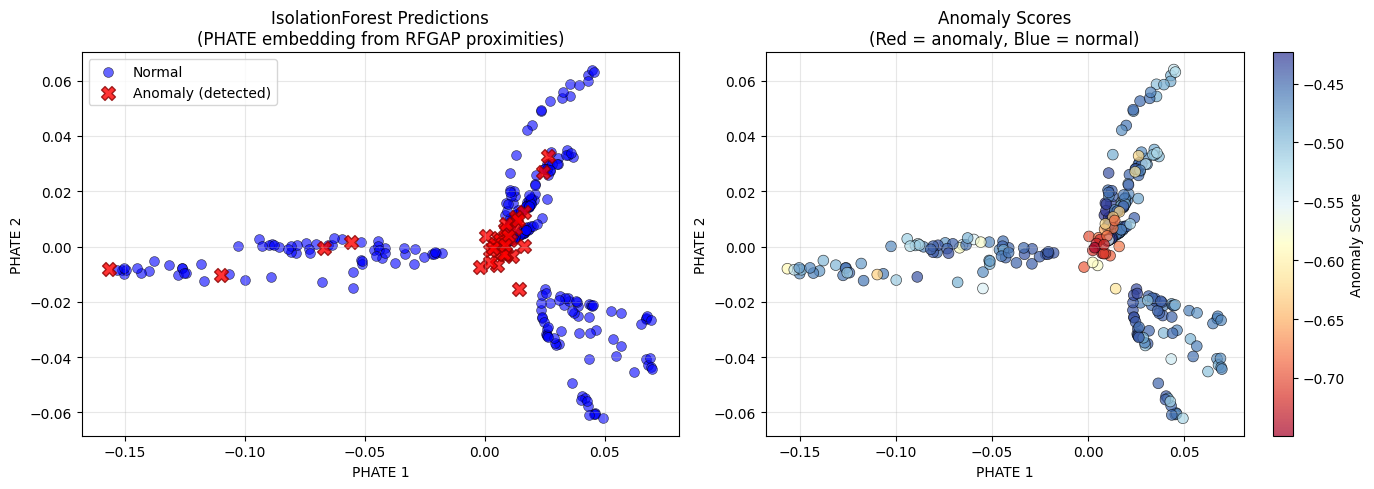

Visualization complete!


In [13]:
# Visualization: PHATE embedding with anomalies highlighted
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: IsolationForest predictions
ax = axes[0]
normal_mask = ~anomaly_mask
ax.scatter(
    embedding[normal_mask, 0],
    embedding[normal_mask, 1],
    c="blue",
    alpha=0.6,
    s=50,
    label="Normal",
    edgecolors="k",
    linewidth=0.5,
)
ax.scatter(
    embedding[anomaly_mask, 0],
    embedding[anomaly_mask, 1],
    c="red",
    alpha=0.8,
    s=100,
    marker="X",
    label="Anomaly (detected)",
    edgecolors="darkred",
    linewidth=1,
)
ax.set_xlabel("PHATE 1")
ax.set_ylabel("PHATE 2")
ax.set_title("IsolationForest Predictions\n(PHATE embedding from RFGAP proximities)")
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 2: Anomaly scores as color gradient
ax = axes[1]
scatter = ax.scatter(
    embedding[:, 0],
    embedding[:, 1],
    c=anomaly_scores,
    cmap="RdYlBu",
    s=60,
    alpha=0.7,
    edgecolors="k",
    linewidth=0.5,
)
ax.set_xlabel("PHATE 1")
ax.set_ylabel("PHATE 2")
ax.set_title("Anomaly Scores\n(Red = anomaly, Blue = normal)")
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("Anomaly Score")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Visualization complete!")

## Summary Statistics

In [9]:
# Calculate metrics
from sklearn.metrics import confusion_matrix, classification_report

# Convert predictions to binary (1 = anomaly, 0 = normal)
y_pred_binary = (predictions == -1).astype(int)

tn, fp, fn, tp = confusion_matrix(y_true, y_pred_binary).ravel()

print("Confusion Matrix:")
print(f"  True Negatives:  {tn}")
print(f"  False Positives: {fp}")
print(f"  False Negatives: {fn}")
print(f"  True Positives:  {tp}")

print(f"\nDetection Metrics:")
print(f"  Precision: {tp / (tp + fp):.3f}" if (tp + fp) > 0 else "  Precision: N/A")
print(f"  Recall:    {tp / (tp + fn):.3f}" if (tp + fn) > 0 else "  Recall: N/A")

print(f"\nAnomaly Score Statistics:")
print(f"  Min:  {anomaly_scores.min():.4f}")
print(f"  Max:  {anomaly_scores.max():.4f}")
print(f"  Mean: {anomaly_scores.mean():.4f}")
print(f"  Std:  {anomaly_scores.std():.4f}")

Confusion Matrix:
  True Negatives:  268
  False Positives: 2
  False Negatives: 2
  True Positives:  28

Detection Metrics:
  Precision: 0.933
  Recall:    0.933

Anomaly Score Statistics:
  Min:  -0.7492
  Max:  -0.4232
  Mean: -0.4818
  Std:  0.0670
